# 5) Interactive Core-Ring Ligand Maps

This notebook generates interactive 2D maps of homoleptic SCO ligands using the reusable descriptor and plotting functions collected in `5a-Core_Ring_Map_Functions.ipynb`.

Notebook 5 now focuses only on map execution; reusable descriptor and rendering functions live in notebook 5a.


In [1]:
%run ./5a-Core_Ring_Map_Functions.ipynb

## 1. Paths


In [2]:
project_path            = Path('/Users/sergivela/Documents/SCOPE/Database_SCO')
root_path               = project_path / 'Analysis/1-Analyse_Database'
outputs_path            = root_path / 'Outputs'
figures_path            = project_path / 'Figures/Grid_Maps'
env_path                = project_path / 'Data/scope_env_atlas.npy'

thermo_csv_path         = outputs_path / 'unique_thermodynamic_data.csv'
bibliography_csv_path   = outputs_path / 'unique_bibliographic_data.csv'

env = scope.read_write.load_binary(str(env_path))

## 2. Load Homoleptic Systems And Data


In [3]:
systems = []
data    = {}
failed_loads = []

for row in read_csv(thermo_csv_path):
    if row.get('homoleptic') != 'True':  continue

    system_path = resolve_system_path(project_path, row['path'])
    try:
        system = scope.read_write.load_binary(str(system_path))
        system.set_paths_from_environment(env)

        biblio_row = filter_rows(bibliography_csv_path, lambda brow: brow["refcode"] == row['refcode'], first=True)

        data[row['refcode']] = {
            'refcode'           : row['refcode'],
            'path'              : row['path'],
            'dHelec [kJ/mol]'   : as_float(row.get('dHelec[kJ/mol]')),
            'dHvib [kJ/mol]'    : as_float(row.get('dHvib[kJ/mol](T=298K)')),
            'dSvibT [kJ/mol]'   : as_float(row.get('dSvib·T[kJ/mol](T=298K)')),
            'dSelecT [kJ/mol]'  : as_float(row.get('dSelec·T[kJ/mol](T=298K)')),
            'dGtot [kJ/mol]'    : as_float(row.get('dGtot[kJ/mol](T=298K)')),
            'T1/2 [K]'          : as_float(row.get('T12[K]')),
            'homoleptic'        : row.get('homoleptic'),
            'denticity'         : row.get('denticity'),
            'authors'           : biblio_row.get('authors'),
            'last_author'       : get_last_author(biblio_row.get('authors')),
            'year'              : biblio_row.get('year'),
            'journal'           : biblio_row.get('journal'),
        }

        systems.append(system)
    except Exception as exc:
        failed_loads.append((row['refcode'], str(system_path), repr(exc)))

print(f'Loaded homoleptic systems: {len(systems)}')
print(f'Succesful loads: {len(data)}')
print(f'Failed loads: {len(failed_loads)}')
failed_loads[:5]

Loaded homoleptic systems: 301
Succesful loads: 301
Failed loads: 0


[]

## 3. Build Ligand Descriptors

This is the only step that uses `descriptor_type`, `weight_alpha`, `fp_radius`, and `fp_n_bits`. The map-generation function below receives these precomputed descriptor records.


In [4]:
# Descriptor controls. These are used only in the descriptor-construction cell below.
descriptor_type = 2      # 1 = unweighted, 2 = distance-weighted Morgan descriptor.
fp_alpha        = 0.25
fp_radius       = 2
fp_n_bits       = 1024

descriptor_records, descriptor_failures = collect_ligands_data(systems,descriptor_type,fp_alpha,fp_radius,fp_n_bits)
print(f'Descriptor records: {len(descriptor_records)}')
print(f'Descriptor failures: {len(descriptor_failures)}')
descriptor_failures[:5]

Descriptor records: 300
Descriptor failures: 1


[('FEPHAK',
  "ValueError('Ligand/RDKit atom mismatch: 35 weights for 36 atoms')")]

## 4. Generate Interactive Map

The tree map keeps family centers in continuous similarity space, whereas the grid map snaps family centers to sparse bins to improve navigation.


In [5]:
def sanitize_filename(text):
    import re
    text = str(text).strip()
    text = text.replace("1/2", "12")
    text = text.replace("/", "_")
    text = text.replace("\\", "_")
    text = re.sub(r"[^A-Za-z0-9._-]+", "_", text)
    text = re.sub(r"_+", "_", text)
    return text.strip("._-")

In [6]:
map_type         = 'grid' # 'tree' or 'grid'
embedding_method = 'mds'  # 'mds' or 'pca'
target_denticities = [1,2,3,6]
properties = ['dHelec', 'T1/2', 'year', 'journal', 'last_author']

for target_denticity in target_denticities:
    for color_property in properties:
        # Tooltip controls. Units are omitted automatically when the value is missing.
        properties_to_show = {
            'Last author': {'key': 'last_author'},
            'Journal': {'key': 'journal'},
            'Year': {'key': 'year', 'digits': 0},
            'dHelec': {'key': 'dHelec', 'unit': 'kJ/mol'},
            'dHvib': {'key': 'dHvib', 'unit': 'kJ/mol'},
            'dSvibT': {'key': 'dSvibT', 'unit': 'kJ/mol'},
            'dGtot': {'key': 'dGtot', 'unit': 'kJ/mol'},
            'T1/2': {'key': 'T1/2', 'unit': 'K'},
        }
    
        common_kwargs = dict(
            descriptor_records=descriptor_records,
            data=data,
            properties_to_show=properties_to_show,
            color_property=color_property,
            target_denticity=target_denticity,
            embedding_method=embedding_method,
            family_min_distance=0.05,
            local_member_min_distance=0.40,
            grid_member_radius=0.40,
            top_n_categories=20,
        )
    
        if map_type == 'tree':
            output_path = figures_path / f'Tree_Map_d{target_denticity}_by_{sanitize_filename(color_property)}'
            map_result  = generate_core_ring_interactive_map(**common_kwargs, grid=False, output_path=output_path) 
        elif map_type == 'grid':
            output_path = figures_path / f'Grid_Map_d{target_denticity}_by_{sanitize_filename(color_property)}'
            map_result  = generate_core_ring_interactive_map(**common_kwargs, grid=True, output_path=output_path) 
        else:
            raise ValueError("map_type must be 'tree' or 'grid'")
    
        print(f"HTML version of Map created in: {map_result['html_path']}")
        print(f"PNG version of Map created in: {map_result['png_path']}")
        print(f"CSV with data stored in: {map_result['csv_path']}")
        print(f"Descriptor failures: {len(descriptor_failures)}")
        print(f"Systems mapped for d={target_denticity}: {len(map_result['map_df'])}")
        print(f"Core-ring families: {len(map_result['family_rows'])}")
        #map_result['map_df'].head()


HTML version of Map created in: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/Grid_Map_d1_by_dHelec.html
PNG version of Map created in: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/Grid_Map_d1_by_dHelec.png
CSV with data stored in: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/Grid_Map_d1_by_dHelec.csv
Descriptor failures: 1
Systems mapped for d=1: 12
Core-ring families: 4


HTML version of Map created in: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/Grid_Map_d1_by_T12.html
PNG version of Map created in: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/Grid_Map_d1_by_T12.png
CSV with data stored in: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/Grid_Map_d1_by_T12.csv
Descriptor failures: 1
Systems mapped for d=1: 12
Core-ring families: 4


HTML version of Map created in: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/Grid_Map_d1_by_year.html
PNG version of Map created in: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/Grid_Map_d1_by_year.png
CSV with data stored in: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/Grid_Map_d1_by_year.csv
Descriptor failures: 1
Systems mapped for d=1: 12
Core-ring families: 4


HTML version of Map created in: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/Grid_Map_d1_by_journal.html
PNG version of Map created in: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/Grid_Map_d1_by_journal.png
CSV with data stored in: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/Grid_Map_d1_by_journal.csv
Descriptor failures: 1
Systems mapped for d=1: 12
Core-ring families: 4


HTML version of Map created in: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/Grid_Map_d1_by_last_author.html
PNG version of Map created in: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/Grid_Map_d1_by_last_author.png
CSV with data stored in: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/Grid_Map_d1_by_last_author.csv
Descriptor failures: 1
Systems mapped for d=1: 12
Core-ring families: 4


HTML version of Map created in: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/Grid_Map_d2_by_dHelec.html
PNG version of Map created in: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/Grid_Map_d2_by_dHelec.png
CSV with data stored in: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/Grid_Map_d2_by_dHelec.csv
Descriptor failures: 1
Systems mapped for d=2: 50
Core-ring families: 22


... (10 outputs left out)

HTML version of Map created in: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/Grid_Map_d6_by_T12.html
PNG version of Map created in: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/Grid_Map_d6_by_T12.png
CSV with data stored in: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/Grid_Map_d6_by_T12.csv
Descriptor failures: 1
Systems mapped for d=6: 31
Core-ring families: 17


HTML version of Map created in: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/Grid_Map_d6_by_year.html
PNG version of Map created in: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/Grid_Map_d6_by_year.png
CSV with data stored in: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/Grid_Map_d6_by_year.csv
Descriptor failures: 1
Systems mapped for d=6: 31
Core-ring families: 17


HTML version of Map created in: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/Grid_Map_d6_by_journal.html
PNG version of Map created in: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/Grid_Map_d6_by_journal.png
CSV with data stored in: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/Grid_Map_d6_by_journal.csv
Descriptor failures: 1
Systems mapped for d=6: 31
Core-ring families: 17


HTML version of Map created in: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/Grid_Map_d6_by_last_author.html
PNG version of Map created in: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/Grid_Map_d6_by_last_author.png
CSV with data stored in: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/Grid_Map_d6_by_last_author.csv
Descriptor failures: 1
Systems mapped for d=6: 31
Core-ring families: 17


## 5. Family-Level $\Delta H_{\mathrm{elec}}$ Statistics and Distributions

For each sufficiently populated ligand family, the main distribution is identified from all systems that passed the project-wide structural filter. The family baseline, $\Delta H_{\mathrm{elec}}^{base}$, is the median of this distribution, while the electronic tunability, $\Delta H_{\mathrm{elec}}^{width}$, is the range spanned by its accepted members.


In [7]:
minimum_central_members  = 6
minimum_central_fraction = 0.60
central_max_gap           = 15.0  # kJ/mol
outlier_iqr_factor        = 1.5

family_statistics = []
family_membership = []

for denticity in [1, 2, 3, 6]:
    denticity_df = pd.read_csv(figures_path / f'Grid_Map_d{denticity}_by_dHelec.csv')
    denticity_df['dHelec [kJ/mol]'] = pd.to_numeric(denticity_df['dHelec [kJ/mol]'], errors='coerce')

    for family_id, family_df in denticity_df.groupby('family_id', sort=False):
        family_df = family_df.dropna(subset=['dHelec [kJ/mol]']).copy()
        if len(family_df) < minimum_central_members:
            continue

        analysis_df = family_df.copy()
        if len(analysis_df) < minimum_central_members:
            continue

        values = analysis_df['dHelec [kJ/mol]']
        q1, q3 = values.quantile([0.25, 0.75])
        preliminary_df = analysis_df[
            values.between(q1 - outlier_iqr_factor * (q3 - q1), q3 + outlier_iqr_factor * (q3 - q1))
        ].sort_values('dHelec [kJ/mol]')

        split_points = np.flatnonzero(
            np.diff(preliminary_df['dHelec [kJ/mol]']) > central_max_gap
        ) + 1
        clusters = np.split(preliminary_df.index.to_numpy(), split_points)
        largest_clusters = [cluster for cluster in clusters if len(cluster) == max(map(len, clusters))]
        if len(largest_clusters) != 1:
            continue

        central_df = analysis_df.loc[largest_clusters[0]].sort_values('dHelec [kJ/mol]')
        if (
            len(central_df) < minimum_central_members
            or len(central_df) / len(analysis_df) < minimum_central_fraction
        ):
            continue

        outside_df = analysis_df.drop(index=central_df.index)
        central_values = central_df['dHelec [kJ/mol]']
        for _, row in analysis_df.iterrows():
            is_main = row.name in central_df.index
            family_membership.append({
                'Denticity': denticity,
                'Family': family_id,
                'Refcode': row['Refcode'],
                'dHelec [kJ/mol]': row['dHelec [kJ/mol]'],
                'Main Distribution': is_main,
                'Classification': 'main' if is_main else 'outside',
            })

        family_statistics.append({
            'Denticity': denticity,
            'Family': family_id,
            'Num Entries': len(family_df),
            'Num Analysed Entries': len(analysis_df),
            'Num Central Entries': len(central_df),
            'Num Outside Central Distribution': len(outside_df),
            'Central Window Min dHelec [kJ/mol]': central_values.min(),
            'Central Window Max dHelec [kJ/mol]': central_values.max(),
            'dHelec Base [kJ/mol]': central_values.median(),
            'dHelec Width [kJ/mol]': central_values.max() - central_values.min(),
        })

family_statistics_df = pd.DataFrame(family_statistics)
family_statistics_df = family_statistics_df.sort_values(['Denticity', 'Family']).reset_index(drop=True)

family_statistics_path = outputs_path / 'ligand_family_dHelec_statistics.csv'
family_statistics_df.round(2).to_csv(family_statistics_path, index=False)

family_membership_df = pd.DataFrame(family_membership)
family_membership_df = family_membership_df.sort_values(['Denticity', 'Family', 'dHelec [kJ/mol]']).reset_index(drop=True)
family_membership_path = outputs_path / 'ligand_family_dHelec_membership.csv'
family_membership_df.round({'dHelec [kJ/mol]': 2}).to_csv(family_membership_path, index=False)

print(f'Families with a central distribution: {len(family_statistics_df)}')
print(f'Family statistics saved to: {family_statistics_path}')
print(f'Family membership saved to: {family_membership_path}')
family_statistics_df.round(2).head(20)


Families with a central distribution: 8
Family statistics saved to: /Users/sergivela/Documents/SCOPE/Database_SCO/Analysis/1-Analyse_Database/Outputs/ligand_family_dHelec_statistics.csv
Family membership saved to: /Users/sergivela/Documents/SCOPE/Database_SCO/Analysis/1-Analyse_Database/Outputs/ligand_family_dHelec_membership.csv


,Denticity,Family,Num Entries,Num Analysed Entries,Num Central Entries,Num Outside Central Distribution,Central Window Min dHelec [kJ/mol],Central Window Max dHelec [kJ/mol],dHelec Base [kJ/mol],dHelec Width [kJ/mol]
0,2,"F(3,1)",7,7,7,0,52.07,57.57,55.37,5.51
1,2,"F(4,1)",11,11,11,0,-3.50,23.54,21.19,27.04
2,3,"F(1,5)",9,9,8,1,2.06,14.79,6.75,12.73
3,3,"F(4,7)",25,25,22,3,44.35,61.92,51.22,17.57
4,3,"F(5,2)",40,40,34,6,13.33,26.41,20.27,13.07
5,3,"F(6,3)",8,8,6,2,53.84,85.26,68.36,31.42
6,3,"F(6,5)",29,29,24,5,11.18,55.95,29.47,44.77
7,6,"F(3,3)",8,8,7,1,2.00,41.38,27.58,39.38


### 5.1 Family-Resolved Distributions

The pale horizontal bands span the electronic tunability, $\Delta H_{\mathrm{elec}}^{width}$, of the accepted main distributions. Orange bands and points show systems outside those distributions. All systems entering this analysis have already passed the project-wide structural filter; no additional structural exclusions are applied here.


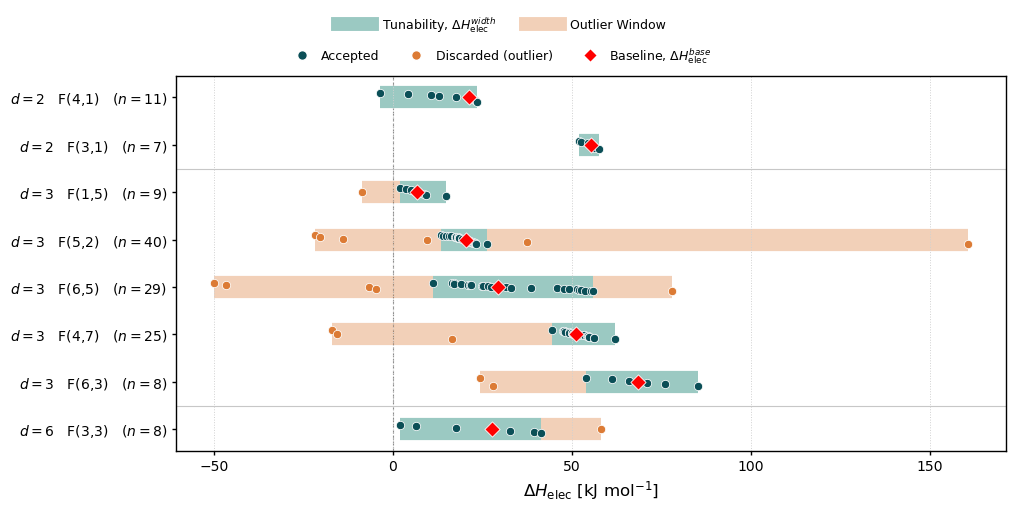

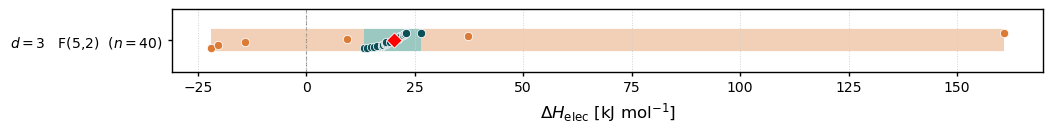

All-family figure saved to: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/dHelec_family_baseline_tunability.png
F(5,2) bpp example saved to: /Users/sergivela/Documents/SCOPE/Database_SCO/Figures/Grid_Maps/dHelec_family_bpp_example.png


In [8]:
from matplotlib.lines import Line2D

baseline_col    = 'dHelec Base [kJ/mol]'
tunability_col  = 'dHelec Width [kJ/mol]'
central_min_col = 'Central Window Min dHelec [kJ/mol]'
central_max_col = 'Central Window Max dHelec [kJ/mol]'

colors = {
    'central_window': '#9bc9c2',
    'central_point': '#0b4f57',
    'outside': '#dc7b35',
}

map_data = {}
for denticity in [1, 2, 3, 6]:
    map_data[denticity] = pd.read_csv(figures_path / f'Grid_Map_d{denticity}_by_dHelec.csv')
    map_data[denticity]['dHelec [kJ/mol]'] = pd.to_numeric(
        map_data[denticity]['dHelec [kJ/mol]'], errors='coerce'
    )

def draw_family_distribution(ax, y, members, statistics):
    values = members['dHelec [kJ/mol]']
    central_min = statistics[central_min_col]
    central_max = statistics[central_max_col]

    if values.min() < central_min:
        ax.plot([values.min(), central_min], [y, y], color=colors['outside'], lw=16,
                alpha=0.35, solid_capstyle='butt', zorder=1)
    if values.max() > central_max:
        ax.plot([central_max, values.max()], [y, y], color=colors['outside'], lw=16,
                alpha=0.35, solid_capstyle='butt', zorder=1)

    ax.plot([central_min, central_max], [y, y], color=colors['central_window'], lw=16,
            solid_capstyle='butt', zorder=1)
    central = values.between(central_min, central_max)
    outside = ~central

    for mask, color in [(central, colors['central_point']), (outside, colors['outside'])]:
        selected = members.loc[mask, 'dHelec [kJ/mol]'].sort_values()
        if selected.empty:
            continue
        offsets = np.linspace(-0.09, 0.09, len(selected)) if len(selected) > 1 else [0.0]
        ax.scatter(selected, y + np.asarray(offsets), s=36, color=color,
                   edgecolor='white', linewidth=0.55, zorder=3)

    ax.scatter(statistics[baseline_col], y, marker='D', s=60, color='red',
               edgecolor='white', linewidth=0.6, zorder=4)


area_handles = [
    Line2D([0], [0], color=colors['central_window'], lw=10,
           label=r'Tunability, $\Delta H_{\mathrm{elec}}^{width}$'),
    Line2D([0], [0], color=colors['outside'], lw=10, alpha=0.35,
           label='Outlier Window'),
]
point_handles = [
    Line2D([0], [0], marker='o', color='none', markerfacecolor=colors['central_point'],
           markeredgecolor='white', markersize=7, label='Accepted'),
    Line2D([0], [0], marker='o', color='none', markerfacecolor=colors['outside'],
           markeredgecolor='white', markersize=7, label='Discarded (outlier)'),
    Line2D([0], [0], marker='D', color='none', markerfacecolor='red',
           markeredgecolor='white', markersize=7,
           label=r'Baseline, $\Delta H_{\mathrm{elec}}^{base}$'),
]

def add_family_legends(fig, fontsize=9):
    fig.legend(
        handles=area_handles, loc='upper center', bbox_to_anchor=(0.5, 0.98),
        ncol=2, frameon=False, fontsize=fontsize, columnspacing=2.4, handlelength=2.7,
    )
    fig.legend(
        handles=point_handles, loc='upper center', bbox_to_anchor=(0.5, 0.92),
        ncol=3, frameon=False, fontsize=fontsize, columnspacing=2.2, handlelength=1.5,
    )


plot_df = family_statistics_df.sort_values(['Denticity', baseline_col]).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10.5, 5.2))
fig.subplots_adjust(left=0.19, right=0.98, bottom=0.12, top=0.84)
for y, (_, statistics) in enumerate(plot_df.iterrows()):
    denticity = int(statistics['Denticity'])
    family = statistics['Family']
    members = map_data[denticity][map_data[denticity]['family_id'].eq(family)].dropna(
        subset=['dHelec [kJ/mol]']
    )
    draw_family_distribution(ax, y, members, statistics)

ax.set_yticks(
    range(len(plot_df)),
    [rf'$d={int(row.Denticity)}$   {row.Family}   $(n={int(row["Num Analysed Entries"])})$'
     for _, row in plot_df.iterrows()],
)
ax.invert_yaxis()
ax.axvline(0, color='0.55', linestyle='--', linewidth=0.8, zorder=0)

for boundary in np.flatnonzero(np.diff(plot_df['Denticity'])) + 0.5:
    ax.axhline(boundary, color='0.78', linewidth=0.8, zorder=0)

ax.set_xlabel(r'$\Delta H_{\mathrm{elec}}$ [kJ mol$^{-1}$]', fontsize=12)
ax.tick_params(direction='out', length=3, width=1)
ax.grid(axis='x', linestyle=':', color='0.82', linewidth=0.7, zorder=0)
for spine in ax.spines.values():
    spine.set_color('black')
    spine.set_linewidth(1.0)
add_family_legends(fig)

all_families_path = figures_path / 'dHelec_family_baseline_tunability.png'
all_families_pdf  = figures_path / 'dHelec_family_baseline_tunability.pdf'
manuscript_all_path = project_path / 'Manuscript/figures/dHelec_family_baseline_tunability.pdf'
plt.savefig(all_families_path, dpi=400, bbox_inches='tight')
plt.savefig(all_families_pdf, bbox_inches='tight')
plt.savefig(manuscript_all_path, bbox_inches='tight')
plt.show()

# Standalone bpp worked example for the ESI.
example_family = map_data[3].loc[map_data[3]['Refcode'].eq('BUTPOY'), 'family_id'].iloc[0]
example = family_statistics_df[
    family_statistics_df['Denticity'].eq(3) & family_statistics_df['Family'].eq(example_family)
].iloc[0]
example_members = map_data[3][map_data[3]['family_id'].eq(example_family)].dropna(
    subset=['dHelec [kJ/mol]']
)

fig, ax = plt.subplots(figsize=(10.5, 2.4))
fig.subplots_adjust(left=0.15, right=0.98, bottom=0.24, top=0.5)
draw_family_distribution(ax, 0, example_members, example)
ax.set_yticks([0], [rf'$d=3$   {example_family}  ($n={int(example["Num Analysed Entries"])}$)'])
ax.set_ylim(-0.36, 0.36)
ax.axvline(0, color='0.55', linestyle='--', linewidth=0.8, zorder=0)
ax.set_xlabel(r'$\Delta H_{\mathrm{elec}}$ [kJ mol$^{-1}$]', fontsize=12)
ax.grid(axis='x', linestyle=':', color='0.82', linewidth=0.7, zorder=0)
ax.tick_params(direction='out', length=3, width=1)
for spine in ax.spines.values():
    spine.set_color('black')
    spine.set_linewidth(1.0)

#ax.text(
#    0.98, 0.08,
#    rf'$\Delta H_{{\mathrm{{elec}}}}^{{base}}={example[baseline_col]:.2f}$ kJ mol$^{{-1}}$'
#    '\n'
#    rf'$\Delta H_{{\mathrm{{elec}}}}^{{width}}={example[tunability_col]:.2f}$ kJ mol$^{{-1}}$',
#    transform=ax.transAxes, ha='right', va='bottom', fontsize=10,
#    bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.88, 'pad': 2.5},
#)
#add_family_legends(fig, fontsize=8.5)

example_path = figures_path / 'dHelec_family_bpp_example.png'
example_pdf  = figures_path / 'dHelec_family_bpp_example.pdf'
manuscript_example_path = project_path / 'Manuscript/figures/dHelec_family_bpp_example.pdf'
plt.savefig(example_path, dpi=400, bbox_inches='tight')
plt.savefig(example_pdf, bbox_inches='tight')
plt.savefig(manuscript_example_path, bbox_inches='tight')
plt.show()

print(f'All-family figure saved to: {all_families_path}')
print(f'{example_family} bpp example saved to: {example_path}')
